In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore") #too many convergence warnings coming from linearsvc
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import recall_score, silhouette_score
from sklearn.cluster import KMeans
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as imbpipeline
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

In [2]:
#linking the dataset
df=pd.read_csv(r"F:\USC_EE\Sem_3\DSCI_552\hw7\Anuran Calls (MFCCs)\Frogs_MFCCs.csv")

In [3]:
print(df.shape) # rows and columns
df.head() #first 5 rows

(7195, 26)


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


In [4]:
#first 22 columns are the MFCC features and Family Genus Species are the 3 labels, recordID we dont need
featurecols = [c for c in df.columns if "MFCC" in c]
labels = ["Family", "Genus", "Species"]
X= df[featurecols]
y= df[labels]
print(len(featurecols))
#checking how many of each class there is in every label
for l in labels:
    print(y[l].value_counts(), "\n")

22
Family
Leptodactylidae    4420
Hylidae            2165
Dendrobatidae       542
Bufonidae            68
Name: count, dtype: int64 

Genus
Adenomera        4150
Hypsiboas        1593
Ameerega          542
Dendropsophus     310
Leptodactylus     270
Scinax            148
Osteocephalus     114
Rhinella           68
Name: count, dtype: int64 

Species
AdenomeraHylaedactylus    3478
HypsiboasCordobae         1121
AdenomeraAndre             672
Ameeregatrivittata         542
HypsiboasCinerascens       472
HylaMinuta                 310
LeptodactylusFuscus        270
ScinaxRuber                148
OsteocephalusOophagus      114
Rhinellagranulosa           68
Name: count, dtype: int64 



In [5]:
#1 a) randomly choosing 70% for train and rest 30 for test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size= 0.3, random_state= 552)
print(X_train.shape, X_test.shape)

(5036, 22) (2159, 22)


In [6]:
#function for exact match and hamming stuff since we have 3 labels per row
def hammingstuff(ytrue, ypred):
    ytrue = np.array(ytrue)
    ypred= np.array(ypred)
    wrong = (ytrue != ypred) #true wherever a lable is predicted wrong
    exactmatch = np.mean(wrong.sum(axis=1)==0) #all 3 correct
    hammingloss = wrong.mean()
    hammingscore = 1- hammingloss
    hammingdistance = wrong.sum(axis=1).mean() #avg number of wrong labels out of 3
    return exactmatch, hammingloss, hammingscore, hammingdistance

allresults = [] #storing every model here to compare at the end

In [7]:
#before grid search checking which range of C and gamma gives atleast 70% train accuracy like the footnote said
#doing it on species since thats the hardest label with 10 classes
for C in [0.01, 0.1, 1, 100, 10000]:
    for g in [0.01, 0.1, 1, 10]:
        m = OneVsRestClassifier(SVC(C=C, gamma=g)).fit(X_train, y_train["Species"])
        print("C:", C, "gamma:", g, "train acc:", round(m.score(X_train, y_train["Species"]), 3))

C: 0.01 gamma: 0.01 train acc: 0.536


C: 0.01 gamma: 0.1 train acc: 0.638


C: 0.01 gamma: 1 train acc: 0.877


C: 0.01 gamma: 10 train acc: 0.9


C: 0.1 gamma: 0.01 train acc: 0.642


C: 0.1 gamma: 0.1 train acc: 0.86


... (10 outputs left out)

C: 10000 gamma: 0.01 train acc: 0.994


C: 10000 gamma: 0.1 train acc: 1.0


C: 10000 gamma: 1 train acc: 1.0


C: 10000 gamma: 10 train acc: 1.0


In [8]:
#1 b ii) guassian kernel svm for each label seperately , one vs all and 10 fold cv
Cvalues = [0.1, 1, 10, 100, 1000]
gammavalues = [0.01, 0.1, 0.5, 1, 2, 5]
param = {"estimator__C": Cvalues, "estimator__gamma": gammavalues}

rbfmodels = {}
rbftable = []
for l in labels:
    grid = GridSearchCV(OneVsRestClassifier(SVC(kernel="rbf")), param, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[l])
    rbfmodels[l] = grid.best_estimator_
    rbftable.append([l, grid.best_params_["estimator__C"], grid.best_params_["estimator__gamma"], grid.best_score_, grid.score(X_test, y_test[l])])

pd.DataFrame(rbftable, columns=["label", "C", "gamma", "cv acc", "test acc"])

,label,C,gamma,cv acc,test acc
0,Family,10,5,0.993645,0.989810
1,Genus,10,2,0.991264,0.988421
2,Species,10,2,0.991264,0.987494


In [9]:
#predicting all 3 labels on the test set and then hamming metrics
rbfpred = pd.DataFrame()
for l in labels:
    rbfpred[l] = rbfmodels[l].predict(X_test)
em, hl, hs, hd = hammingstuff(y_test, rbfpred)
print("exact match:", round(em,4), "hamming loss:", round(hl,4), "hamming score:", round(hs,4), "hamming distance:", round(hd,4))
allresults.append(["RBF svm raw", em, hl, hs, hd])

exact match: 0.9843 hamming loss: 0.0114 hamming score: 0.9886 hamming distance: 0.0343


In [10]:
#same thing but now standarizing the features first, putting scaler in pipeline so it only fits on training folds
paramstd = {"svm__estimator__C": Cvalues, "svm__estimator__gamma": gammavalues}

rbfstdmodels = {}
rbfstdtable = []
for l in labels:
    pipe = Pipeline([("scaler", StandardScaler()), ("svm", OneVsRestClassifier(SVC(kernel="rbf")))])
    grid = GridSearchCV(pipe, paramstd, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[l])
    rbfstdmodels[l] = grid.best_estimator_
    rbfstdtable.append([l, grid.best_params_["svm__estimator__C"], grid.best_params_["svm__estimator__gamma"], grid.best_score_, grid.score(X_test, y_test[l])])

pd.DataFrame(rbfstdtable, columns=["label", "C", "gamma", "cv acc", "test acc"])

,label,C,gamma,cv acc,test acc
0,Family,10,0.1,0.991462,0.990273
1,Genus,10,0.1,0.988683,0.988421
2,Species,100,0.1,0.987690,0.987031


In [11]:
rbfstdpred = pd.DataFrame()
for l in labels:
    rbfstdpred[l] = rbfstdmodels[l].predict(X_test)
em, hl, hs, hd = hammingstuff(y_test, rbfstdpred)
print("exact match:", round(em,4), "hamming loss:", round(hl,4), "hamming score:", round(hs,4), "hamming distance:", round(hd,4))
allresults.append(["RBF svm standarized", em, hl, hs, hd])

exact match: 0.9847 hamming loss: 0.0114 hamming score: 0.9886 hamming distance: 0.0343


In [12]:
#1 b iii) L1 penalized linear svm , LinearSVC is already one vs rest by default
#features have to be standarized here
Cl1 = [0.001, 0.01, 0.1, 1, 10, 100]

l1models = {}
l1table = []
for l in labels:
    pipe = Pipeline([("scaler", StandardScaler()), ("svm", LinearSVC(penalty="l1", dual=False, max_iter=5000))])
    grid = GridSearchCV(pipe, {"svm__C": Cl1}, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[l])
    l1models[l] = grid.best_estimator_
    l1table.append([l, grid.best_params_["svm__C"], grid.best_score_, grid.score(X_test, y_test[l])])

pd.DataFrame(l1table, columns=["label", "C", "cv acc", "test acc"])

,label,C,cv acc,test acc
0,Family,1,0.938644,0.933302
1,Genus,10,0.953937,0.952293
2,Species,10,0.958898,0.956461


In [13]:
l1pred = pd.DataFrame()
for l in labels:
    l1pred[l] = l1models[l].predict(X_test)
em, hl, hs, hd = hammingstuff(y_test, l1pred)
print("exact match:", round(em,4), "hamming loss:", round(hl,4), "hamming score:", round(hs,4), "hamming distance:", round(hd,4))
allresults.append(["L1 svm", em, hl, hs, hd])

exact match: 0.9171 hamming loss: 0.0526 hamming score: 0.9474 hamming distance: 0.1579


In [14]:
#1 b iv) SMOTE for the imbalance, using imblearn pipeline so smote only happens on the training folds and not on validation
smotemodels = {}
smotetable = []
for l in labels:
    pipe = imbpipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=552)), ("svm", LinearSVC(penalty="l1", dual=False, max_iter=5000))])
    grid = GridSearchCV(pipe, {"svm__C": Cl1}, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[l])
    smotemodels[l] = grid.best_estimator_
    smotetable.append([l, grid.best_params_["svm__C"], grid.best_score_, grid.score(X_test, y_test[l])])

pd.DataFrame(smotetable, columns=["label", "C", "cv acc", "test acc"])

,label,C,cv acc,test acc
0,Family,100,0.920969,0.913386
1,Genus,10,0.919578,0.911070
2,Species,100,0.955520,0.950440


In [15]:
smotepred = pd.DataFrame()
for l in labels:
    smotepred[l] = smotemodels[l].predict(X_test)
em, hl, hs, hd = hammingstuff(y_test, smotepred)
print("exact match:", round(em,4), "hamming loss:", round(hl,4), "hamming score:", round(hs,4), "hamming distance:", round(hd,4))
allresults.append(["L1 svm + SMOTE", em, hl, hs, hd])

exact match: 0.8638 hamming loss: 0.075 hamming score: 0.925 hamming distance: 0.2251


In [16]:
#checking if smote actually helped the small classes, recall for each species with and without smote
specieslist = sorted(y["Species"].unique())
recalltable = pd.DataFrame({
    "without smote": recall_score(y_test["Species"], l1pred["Species"], average=None, labels=specieslist),
    "with smote": recall_score(y_test["Species"], smotepred["Species"], average=None, labels=specieslist)}, index=specieslist)
recalltable["count in test"] = y_test["Species"].value_counts()
recalltable.round(3)

,without smote,with smote,count in test
AdenomeraAndre,0.926,0.897,203
AdenomeraHylaedactylus,0.996,0.994,1045
Ameeregatrivittata,0.956,0.911,158
HylaMinuta,0.663,0.798,89
HypsiboasCinerascens,0.971,0.935,139
HypsiboasCordobae,0.963,0.942,347
LeptodactylusFuscus,0.893,0.893,84
OsteocephalusOophagus,0.667,0.778,27
Rhinellagranulosa,0.900,0.900,20
ScinaxRuber,0.979,0.957,47


In [17]:
#all the models side by side
pd.DataFrame(allresults, columns=["model", "exact match", "hamming loss", "hamming score", "hamming distance"])

,model,exact match,hamming loss,hamming score,hamming distance
0,RBF svm raw,0.984252,0.011425,0.988575,0.034275
1,RBF svm standarized,0.984715,0.011425,0.988575,0.034275
2,L1 svm,0.917091,0.052648,0.947352,0.157943
3,L1 svm + SMOTE,0.863826,0.075035,0.924965,0.225104


In [18]:
#2) kmeans on the whole dataset , using all the MFCC columns
Xall = df[featurecols]

#gives every point in a cluster the majority family genus and species of that cluster
def majoritylabels(clusters):
    pred = y.copy()
    for c in np.unique(clusters):
        for l in labels:
            majority = y.loc[clusters==c, l].mode()[0]
            pred.loc[clusters==c, l] = majority
    return pred

In [19]:
#monte carlo 50 times, every time choose k from 2 to 15 using silhouette score
#used sample_size in silhouette becuase full data was taking forever
krange = range(2, 16)
mcresults = []
for run in range(50):
    silscores = []
    kmlist = []
    for k in krange:
        km = KMeans(n_clusters=k, n_init=10, random_state=run).fit(Xall)
        silscores.append(silhouette_score(Xall, km.labels_, sample_size=3000, random_state=run))
        kmlist.append(km)
    bestk = krange[np.argmax(silscores)]
    clusters = kmlist[np.argmax(silscores)].labels_
    pred = majoritylabels(clusters)
    em, hl, hs, hd = hammingstuff(y, pred)
    mcresults.append([run, bestk, em, hl, hs, hd])
    print(run, "best k:", bestk)  #just to see progress

mc = pd.DataFrame(mcresults, columns=["run", "k", "exact match", "hamming loss", "hamming score", "hamming distance"])
mc.head()

0 best k: 4


1 best k: 4


2 best k: 4


3 best k: 4


4 best k: 4


5 best k: 4


... (41 outputs left out)

47 best k: 4


48 best k: 4


49 best k: 4


,run,k,exact match,hamming loss,hamming score,hamming distance
0,0,4,0.755525,0.222423,0.777577,0.667269
1,1,4,0.755525,0.222423,0.777577,0.667269
2,2,4,0.682974,0.245124,0.754876,0.735372
3,3,4,0.755525,0.222423,0.777577,0.667269
4,4,4,0.755525,0.222423,0.777577,0.667269


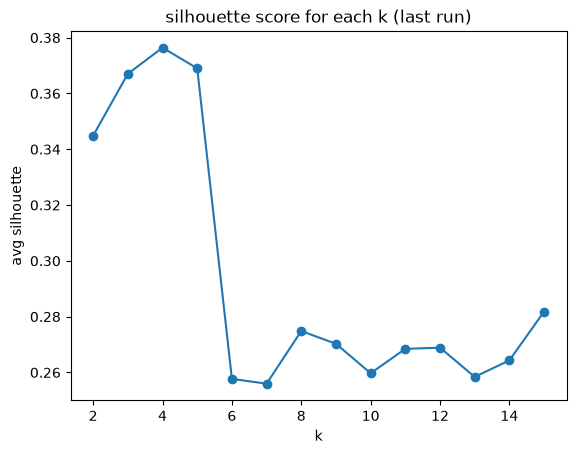

In [20]:
#silhouette vs k for the last run
plt.plot(list(krange), silscores, marker="o")
plt.xlabel("k")
plt.ylabel("avg silhouette")
plt.title("silhouette score for each k (last run)")
plt.show()

In [21]:
#2 b) majority family genus species in each cluster , last run
temp = y.copy()
temp["cluster"] = clusters
majoritytable = temp.groupby("cluster").agg(lambda s: s.mode()[0])
majoritytable["size"] = temp["cluster"].value_counts()
majoritytable

,Family,Genus,Species,size
cluster,,,,
0,Hylidae,Hypsiboas,HypsiboasCinerascens,614
1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3568
2,Hylidae,Hypsiboas,HypsiboasCordobae,1982
3,Dendrobatidae,Ameerega,Ameeregatrivittata,1031


In [22]:
#2 c,d) average and standard deviation of hamming over the 50 runs
print(mc["k"].value_counts())
mc[["hamming distance", "hamming score", "hamming loss", "exact match"]].agg(["mean", "std"])

k
4    50
Name: count, dtype: int64


,hamming distance,hamming score,hamming loss,exact match
mean,0.671889,0.776037,0.223963,0.750666
std,0.016978,0.005659,0.005659,0.017752


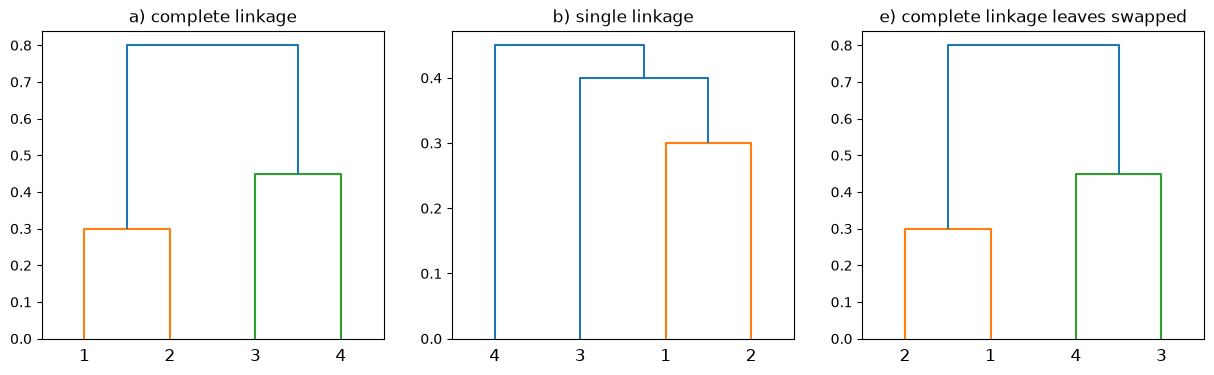

[[0.   1.   0.3  2.  ]
 [2.   3.   0.45 2.  ]
 [4.   5.   0.8  4.  ]]
[[0.   1.   0.3  2.  ]
 [2.   4.   0.4  3.  ]
 [3.   5.   0.45 4.  ]]
c) complete 2 clusters: [1 1 2 2]
d) single 2 clusters: [1 1 1 2]


In [23]:
#3) ISLR 12.6.2 dissimilarity matrix from the question
D = np.array([[0, 0.3, 0.4, 0.7],
              [0.3, 0, 0.5, 0.8],
              [0.4, 0.5, 0, 0.45],
              [0.7, 0.8, 0.45, 0]])
#linkage needs the condensed form
dcondensed = squareform(D)
complete = linkage(dcondensed, "complete")
single = linkage(dcondensed, "single")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
dendrogram(complete, labels=[1, 2, 3, 4], ax=ax[0])
ax[0].set_title("a) complete linkage")
dendrogram(single, labels=[1, 2, 3, 4], ax=ax[1])
ax[1].set_title("b) single linkage")
#e) same complete tree but swapping 1 with 2 and 3 with 4
order = [1, 0, 3, 2]
dendrogram(linkage(squareform(D[order][:, order]), "complete"), labels=[2, 1, 4, 3], ax=ax[2])
ax[2].set_title("e) complete linkage leaves swapped")
plt.show()

print(complete)
print(single)
print("c) complete 2 clusters:", fcluster(complete, 2, "maxclust"))
print("d) single 2 clusters:", fcluster(single, 2, "maxclust"))

Now answering all the questions that were theoritical

1 b i
exact match = a row is counted correct only if all 3 labels family genus and species are correct , so its the strictest one
hamming loss = out of all the individual labels (n rows x 3 labels) what fraction got predicted wrong
hamming score = 1 - hamming loss, so fraction of labels that are right
hamming distance = for each row how many of the 3 labels are wrong (0,1,2 or 3) , i took the average over all rows

1 b ii
Checked the range first like the footnote said , train accuracy was above 70% for almost everything except very small C with small gamma (C=0.01 gamma 0.01 gave 0.536)
so i used C from 0.1 to 1000 and gamma from 0.01 to 5

raw data best was C=10 and gamma 5 for family and gamma 2 for genus and species
standarized best was gamma 0.1 for all and C = 10 ,10 ,100
exact match raw = 0.9843 and standarized = 0.9847 , hamming loss 0.0114 for both
So standarizing didnt really change anything , the MFCCs are already between -1 and 1 so scaling just changes what gamma value is best

1 b iii
L1 svm best C was 1 for family and 10 for genus and species
exact match = 0.917 , hamming loss = 0.053
around 7% worse than gaussian kernel, which means the classes are not linearly seperable that well in the 22 features , family was the worst label with 0.933 test acc

1 b iv
with SMOTE exact match went down to 0.864 and hamming loss went up to 0.075
BUT the small species did get better recall
HylaMinuta 0.663 -> 0.798
Osteocephalus 0.667 -> 0.778
Rhinella stayed same 0.9
while the big classes went down a little bit (AdenomeraAndre 0.926 -> 0.897)
so smote helps the minority classes but overall accuracy drops becuase it starts predicting the small classes more often , depends on what we care about

Gaussian svm is the best by far for this dataset , imbalance doesnt hurt it much

2 a
silhouette picked k = 4 in all 50 runs (checked k from 2 to 15)

2 b
the 4 clusters majority labels for the last run were
Leptodactylidae, Adenomera, AdenomeraHylaedactylus (biggest cluster 3568)
Hylidae, Hypsiboas, HypsiboasCordobae
Hylidae, Hypsiboas, HypsiboasCinerascens
Dendrobatidae, Ameerega, Ameeregatrivittata
so the small species like Rhinella , Scinax, Osteocephalus never become majority anywhere which means they are always wrong

2 c , d
over 50 runs
hamming distance = 0.672 +- 0.017
hamming score = 0.776 +- 0.006
hamming loss = 0.224 +- 0.006
exact match = 0.751 +- 0.018
std is very small since most runs land on the same clusters , only some seeds were different (like run 2)
way worse than the svm ofcourse since kmeans doesnt use the labels at all

3 ISLR 12.6.2
a) complete linkage
1 and 2 fuse first at 0.3
then {1,2} to 3 = max(0.4,0.5) = 0.5 and {1,2} to 4 = 0.8 , 3 to 4 = 0.45 so 3 and 4 fuse at 0.45
then both fuse at max = 0.8

b) single linkage
1 and 2 fuse at 0.3
{1,2} to 3 = min(0.4,0.5) = 0.4 which is smallest so 3 joins at 0.4
then 4 joins at min(0.7,0.8,0.45) = 0.45

c) cutting complete into 2 clusters gives {1,2} and {3,4}

d) cutting single into 2 clusters gives {1,2,3} and {4}

e) we can swap the two branches at any fusion without changing the meaning , so swapping 1 with 2 and 3 with 4 gives leaves 2,1,4,3 same heights same tree just looks different (third plot)
